# Prediksi Klaim Asuransi Kesehatan Individu — AXA Financial Indonesia
### Data Science Project · Frequency, Severity & Total Claim

**Konteks bisnis.** Klaim asuransi kesehatan individu naik ~25.5% (Jan–Jun 2025 vs 2024).
Kenaikan klaim mendorong penyesuaian premi yang membuat produk jadi kurang terjangkau.
Perusahaan butuh analisa berbasis data untuk memahami **apa yang mendorong besar (severity)
dan seringnya (frequency) klaim**, lalu **memproyeksikan tren klaim** agar bisa mengambil
langkah di sisi seleksi risiko, pencegahan, dan penetapan harga.

**Tujuan notebook ini.**
1. Eksplorasi & pembersihan data klaim.
2. Identifikasi faktor pendorong **severity** dan **frequency** klaim.
3. Bangun & bandingkan model untuk memproyeksikan tren **frequency, severity, dan total claim**.
4. Evaluasi model dengan metrik yang sesuai (**MAPE**) dan berikan rekomendasi.

**Prinsip desain.** Satu alur data yang lurus, tanpa kebocoran target (*data leakage*), dan
memilih model **sesederhana mungkin yang bisa dipertanggungjawabkan** — karena data bulanan
hanya ~19 titik dan relatif datar, model yang terlalu kompleks justru *overfitting*.


## 1. Setup

Impor pustaka sekali di awal. Semua sel setelah ini mengandalkan impor di sini.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score

import warnings
warnings.filterwarnings("ignore")

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)
RANDOM_STATE = 42


def mape(y_true, y_pred):
    """Mean Absolute Percentage Error (%). Metrik resmi kompetisi.
    Baris dengan nilai aktual 0 diabaikan agar tidak membagi nol."""
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    mask = y_true != 0
    return np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100


## 2. Load Data

Dua sumber data:
- **`Data_Polis.csv`** — 1 baris per polis (profil nasabah): plan, gender, tanggal lahir,
  tanggal efektif polis, domisili.
- **`Data_Klaim.csv`** — 1 baris per klaim: nominal, jenis rawat, diagnosis (ICD),
  tanggal masuk/keluar RS, lokasi RS, dll.

In [2]:
df_polis = pd.read_csv("Data_Polis.csv")
df_klaim = pd.read_csv("Data_Klaim.csv")

print("Data Polis :", df_polis.shape)
print("Data Klaim :", df_klaim.shape)
df_klaim.head()


Data Polis : (4096, 6)
Data Klaim : (4627, 13)


,Claim ID,Nomor Polis,Reimburse/Cashless,Inpatient/Outpatient,ICD Diagnosis,ICD Description,Status Klaim,Tanggal Pembayaran Klaim,Tanggal Pasien Masuk RS,Tanggal Pasien Keluar RS,Nominal Klaim Yang Disetujui,Nominal Biaya RS Yang Terjadi,Lokasi RS
0,C-0001-M,POL-0176,R,OP,C50,MALIGNANT NEOPLASM OF BREAST,PAID,2024-07-08,2024-05-27,2024-05-27,28093653.0,6.143948e+06,Singapore
1,C-0002-M,POL-3288,R,OP,C34,MALIGNANT NEOPLASM OF BRONCHUS AND LUNG,PAID,2024-08-06,2024-07-15,2024-07-15,80987278.0,8.230952e+07,Malaysia
2,C-0003-M,POL-1786,R,OP,C18.9,"MALIGNANT NEOPLASM, COLON, UNSPECIFIED",PAID,2024-10-17,2024-05-16,2024-05-16,183047130.0,1.928599e+08,Singapore
3,C-0004-M,POL-1786,R,OP,C34,MALIGNANT NEOPLASM OF BRONCHUS AND LUNG,PAID,2024-09-03,2024-07-18,2024-07-18,191424386.0,1.914244e+08,Singapore
4,C-0005-M,POL-2778,R,OP,C50,MALIGNANT NEOPLASM OF BREAST,PAID,NaN,2024-06-06,2024-06-06,138936357.0,1.389364e+08,Singapore


## 3. Data Understanding & Pembersihan

### 3.1 Tipe data & tanggal
Kolom tanggal masih berupa teks/angka. Tanggal di data polis berformat `YYYYMMDD`
(mis. `19640811`), sedangkan di data klaim sudah ISO (`YYYY-MM-DD`). Kita ubah ke `datetime`
supaya bisa dihitung selisihnya (umur, lama rawat, durasi polis).

In [3]:
# Data Polis: format YYYYMMDD
for c in ["Tanggal Lahir", "Tanggal Efektif Polis"]:
    df_polis[c] = pd.to_datetime(df_polis[c].astype(str), format="%Y%m%d", errors="coerce")

# Data Klaim: format ISO
for c in ["Tanggal Pembayaran Klaim", "Tanggal Pasien Masuk RS", "Tanggal Pasien Keluar RS"]:
    df_klaim[c] = pd.to_datetime(df_klaim[c], errors="coerce")

# Nominal ke numerik (jaga-jaga bila ada teks)
for c in ["Nominal Klaim Yang Disetujui", "Nominal Biaya RS Yang Terjadi"]:
    df_klaim[c] = pd.to_numeric(df_klaim[c], errors="coerce")

df_polis.dtypes


Nomor Polis                         str
Plan Code                           str
Gender                              str
Tanggal Lahir            datetime64[us]
Tanggal Efektif Polis    datetime64[us]
Domisili                            str
dtype: object

### 3.2 Missing value & duplikat
Cek kelengkapan dan duplikasi. Nomor Polis harus unik di data polis (berfungsi sebagai
*primary key*).

In [4]:
print("Missing value per kolom (Klaim):")
print(df_klaim.isna().sum()[df_klaim.isna().sum() > 0])
print()
print("Duplikat polis :", df_polis.duplicated().sum())
print("Duplikat klaim :", df_klaim.duplicated().sum())
print("Nomor Polis unik:", df_polis["Nomor Polis"].is_unique)


Missing value per kolom (Klaim):
Inpatient/Outpatient        37
ICD Diagnosis                6
ICD Description              6
Tanggal Pembayaran Klaim    37
Lokasi RS                    7
dtype: int64

Duplikat polis : 0
Duplikat klaim : 0
Nomor Polis unik: True


### 3.3 Pemeriksaan konsistensi & nilai janggal
- Tanggal masuk RS tidak boleh setelah tanggal keluar RS.
- Ada klaim dengan nominal disetujui = 0 (kemungkinan klaim ditolak/tidak dibayar).
- Semua klaim berstatus `PAID`, jadi kita tidak bisa memodelkan probabilitas persetujuan;
  fokus analisis ada di **frekuensi** dan **severity** klaim yang sudah terjadi.

In [5]:
invalid_date = (df_klaim["Tanggal Pasien Masuk RS"] > df_klaim["Tanggal Pasien Keluar RS"]).sum()
zero_claim = (df_klaim["Nominal Klaim Yang Disetujui"] <= 0).sum()

print("Tanggal masuk > keluar :", invalid_date)
print("Klaim nominal <= 0     :", zero_claim)
print("Status klaim unik      :", df_klaim["Status Klaim"].unique())
print("Rentang tanggal klaim  :",
      df_klaim["Tanggal Pasien Masuk RS"].min().date(), "->",
      df_klaim["Tanggal Pasien Masuk RS"].max().date())


Tanggal masuk > keluar : 0
Klaim nominal <= 0     : 13
Status klaim unik      : <StringArray>
['PAID']
Length: 1, dtype: str
Rentang tanggal klaim  : 2024-01-01 -> 2025-07-31


**Catatan:** data klaim aktual membentang **Januari 2024 – Juli 2025 (19 bulan)**.
Prediksi Agustus–Desember 2025 karenanya benar-benar *out-of-sample* (di luar data latih).

## 4. Feature Engineering (level klaim)

Kita gabung klaim + polis menjadi **satu tabel level klaim**, lalu bangun fitur turunan yang
punya makna aktuaria. Semua dihitung relatif ke **tanggal klaim** (bukan tanggal hari ini),
supaya nilainya konsisten secara historis.

| Fitur | Definisi | Kenapa relevan |
|---|---|---|
| `umur` | umur nasabah saat klaim | risiko kesehatan naik seiring usia |
| `los` | lama rawat (hari) = keluar − masuk | proxy tingkat keparahan |
| `tenure` | durasi polis saat klaim (tahun) | eksposur & perilaku klaim |
| `icd_chapter` | huruf pertama kode ICD (bab penyakit) | jenis penyakit → biaya berbeda |
| `month` | bulan klaim | menangkap pola musiman |

> **Penting (anti-leakage):** kita **tidak** memakai `Nominal Biaya RS`, selisih biaya, atau
> transformasi log dari nominal klaim sebagai fitur. Nilai-nilai itu turunan dari target
> (nominal klaim) dan akan membocorkan jawaban ke model.

In [6]:
df = df_klaim.merge(df_polis, on="Nomor Polis", how="left")

# Tanggal acuan = tanggal masuk RS
df["claim_date"] = df["Tanggal Pasien Masuk RS"]
df["year_month"] = df["claim_date"].dt.to_period("M").astype(str)
df["month"] = df["claim_date"].dt.month

# Fitur turunan
df["los"] = (df["Tanggal Pasien Keluar RS"] - df["Tanggal Pasien Masuk RS"]).dt.days.clip(lower=0)
df["umur"] = ((df["claim_date"] - df["Tanggal Lahir"]).dt.days / 365.25).round(1)
df["tenure"] = ((df["claim_date"] - df["Tanggal Efektif Polis"]).dt.days / 365.25).clip(lower=0).round(2)

# Bab ICD = huruf pertama kode diagnosis (mis. 'C50' -> 'C' = neoplasma)
df["icd_chapter"] = df["ICD Diagnosis"].astype(str).str[0].str.upper()

# Target severity (nominal klaim yang disetujui)
df["severity"] = df["Nominal Klaim Yang Disetujui"]

df[["Nomor Polis", "year_month", "umur", "los", "tenure", "icd_chapter", "severity"]].head()


,Nomor Polis,year_month,umur,los,tenure,icd_chapter,severity
0,POL-0176,2024-05,57.3,0,9.38,C,28093653.0
1,POL-3288,2024-07,67.8,0,12.07,C,80987278.0
2,POL-1786,2024-05,64.6,0,9.17,C,183047130.0
3,POL-1786,2024-07,64.7,0,9.34,C,191424386.0
4,POL-2778,2024-06,55.7,0,9.95,C,138936357.0


## 5. Exploratory Data Analysis

### 5.1 Distribusi nominal klaim (severity)
Nominal klaim sangat *right-skewed* / *heavy-tailed*: mayoritas kecil, sebagian kecil sangat
besar (hingga miliaran). Karena itu skala **log** jauh lebih informatif, dan model severity
sebaiknya dilatih pada `log(severity)`.

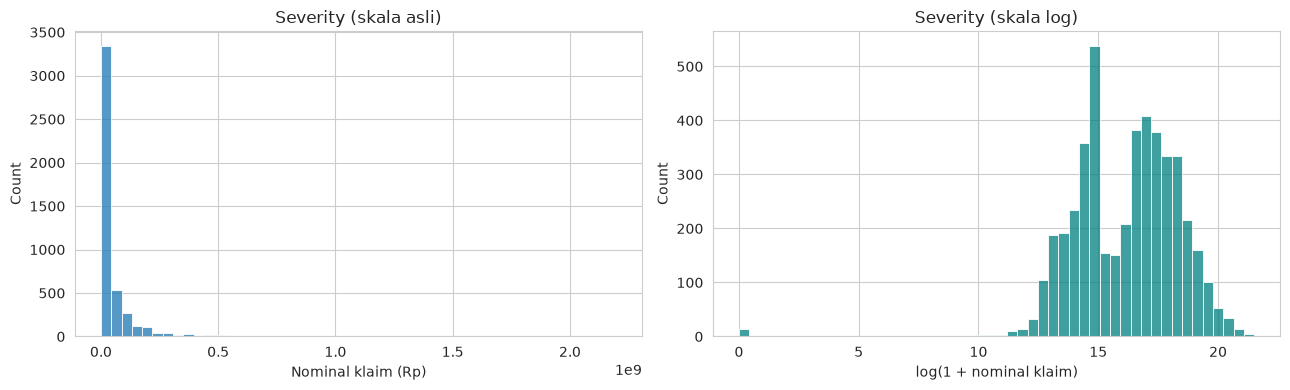

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df["severity"], bins=50, ax=ax[0])
ax[0].set(title="Severity (skala asli)", xlabel="Nominal klaim (Rp)")
sns.histplot(np.log1p(df["severity"]), bins=50, ax=ax[1], color="teal")
ax[1].set(title="Severity (skala log)", xlabel="log(1 + nominal klaim)")
plt.tight_layout(); plt.show()


### 5.2 Tren bulanan: frekuensi, severity, total
Frekuensi bulanan **stabil** (~230–270 klaim/bulan) tanpa tren naik yang jelas. Severity dan
total lebih berfluktuasi (dipengaruhi klaim ekstrem). Ini sinyal penting untuk pemodelan:
seri relatif datar → **model sederhana sudah memadai**, model kompleks berisiko overfit.

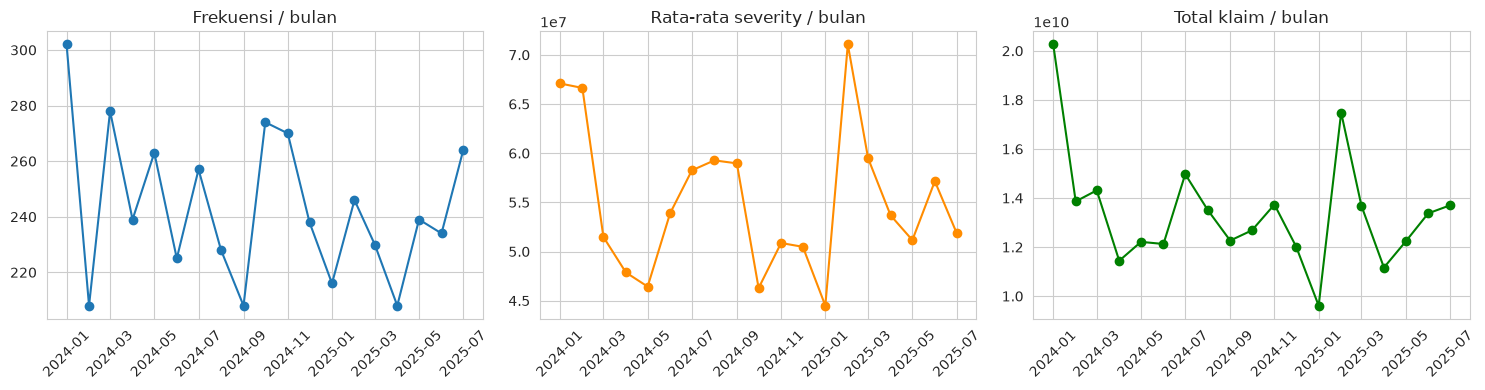

In [8]:
_m = df.groupby("year_month").agg(
    frequency=("Claim ID", "count"),
    severity=("severity", "mean"),
).reset_index()
_m["total_claim"] = _m["frequency"] * _m["severity"]
_m["ds"] = pd.to_datetime(_m["year_month"])

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(_m["ds"], _m["frequency"], marker="o"); ax[0].set(title="Frekuensi / bulan")
ax[1].plot(_m["ds"], _m["severity"], marker="o", color="darkorange"); ax[1].set(title="Rata-rata severity / bulan")
ax[2].plot(_m["ds"], _m["total_claim"], marker="o", color="green"); ax[2].set(title="Total klaim / bulan")
for a in ax: a.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()


### 5.3 Severity menurut kategori
Membandingkan median severity antar kategori membantu menebak faktor pendorong biaya.
Biasanya rawat inap (IP), lokasi RS luar negeri, dan bab penyakit tertentu (mis. neoplasma)
punya severity lebih tinggi.

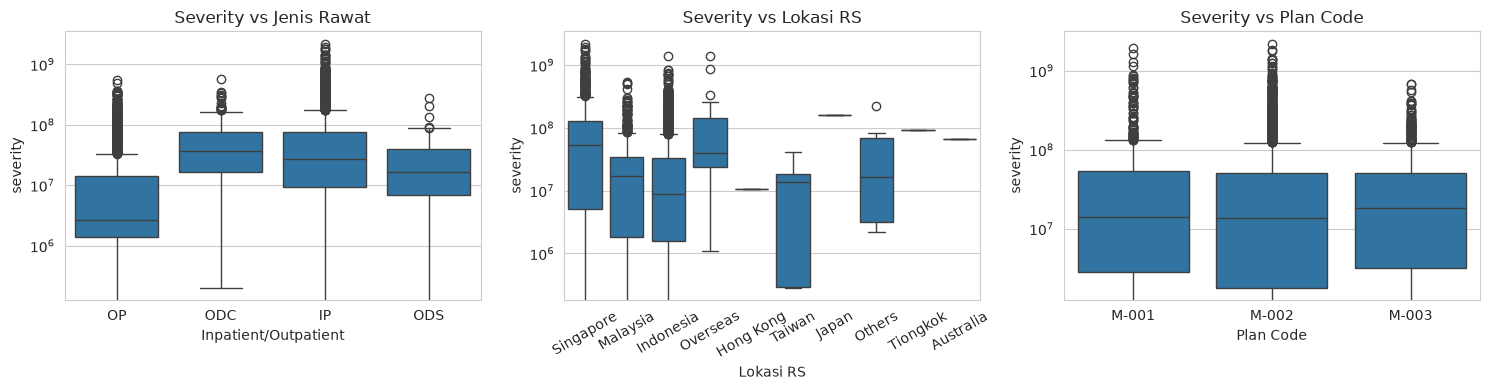

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.boxplot(data=df, x="Inpatient/Outpatient", y="severity", ax=ax[0]); ax[0].set_yscale("log"); ax[0].set(title="Severity vs Jenis Rawat")
sns.boxplot(data=df, x="Lokasi RS", y="severity", ax=ax[1]); ax[1].set_yscale("log"); ax[1].tick_params(axis="x", rotation=30); ax[1].set(title="Severity vs Lokasi RS")
sns.boxplot(data=df, x="Plan Code", y="severity", ax=ax[2]); ax[2].set_yscale("log"); ax[2].set(title="Severity vs Plan Code")
plt.tight_layout(); plt.show()


### 5.4 Severity menurut kelompok umur
Membandingkan rata-rata severity per kelompok umur untuk melihat pola usia.

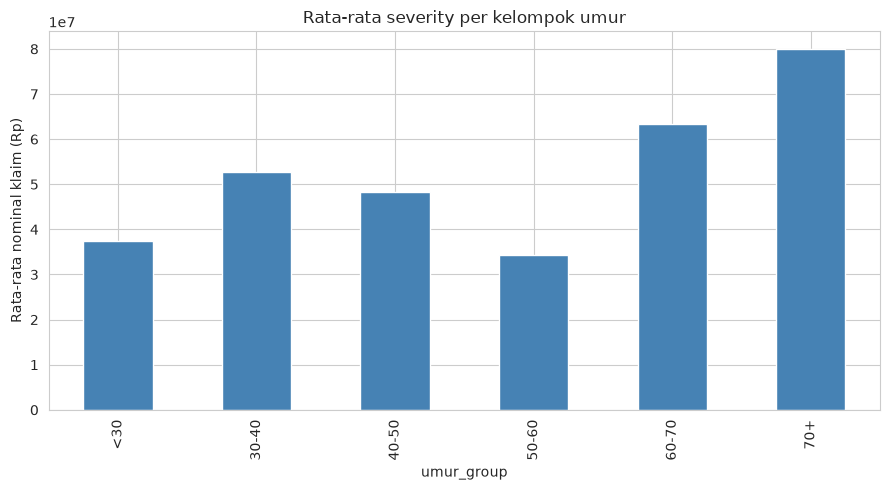

In [10]:
df["umur_group"] = pd.cut(df["umur"], bins=[0, 30, 40, 50, 60, 70, 120],
                          labels=["<30", "30-40", "40-50", "50-60", "60-70", "70+"])
sev_age = df.groupby("umur_group")["severity"].mean()

sev_age.plot(kind="bar", color="steelblue")
plt.title("Rata-rata severity per kelompok umur"); plt.ylabel("Rata-rata nominal klaim (Rp)")
plt.tight_layout(); plt.show()


## 6. Faktor Pendorong Severity & Frequency

Kita jawab dua pertanyaan inti case: **apa yang mendorong severity** dan **apa yang mendorong
frequency**. Pendekatannya: latih model, lalu baca **feature importance**-nya.

### 6.1 Faktor pendorong SEVERITY (level klaim)

Target: `log(1 + severity)`. Fitur: karakteristik klaim & nasabah yang **diketahui saat klaim
terjadi** dan **bukan turunan dari nominal klaim** (anti-leakage).

Domisili punya banyak kategori, jadi kita kelompokkan hanya kota terbesar + `LAINNYA` agar
one-hot encoding tidak meledak.

In [11]:
# Kelompokkan domisili jarang
top_dom = df["Domisili"].value_counts().head(6).index
df["domisili_grp"] = np.where(df["Domisili"].isin(top_dom), df["Domisili"], "LAINNYA")

base_features = ["Reimburse/Cashless", "Inpatient/Outpatient", "Lokasi RS",
                 "Plan Code", "Gender", "domisili_grp"]          # tanpa feature engineering
eng_features = ["umur", "los", "tenure", "icd_chapter", "month"]  # hasil feature engineering

y_sev = np.log1p(df["severity"])


def make_X(cols):
    """One-hot encode daftar kolom menjadi matriks fitur numerik."""
    return pd.get_dummies(df[cols], drop_first=True)


### 6.2 Perbandingan: dengan vs tanpa feature engineering
Case meminta perbandingan hasil **dengan dan tanpa feature engineering**. Kita latih model yang
sama pada dua set fitur dan bandingkan performanya di data uji (R² & MAE pada skala log).

In [12]:
def eval_severity(cols, label):
    X = make_X(cols)
    Xtr, Xte, ytr, yte = train_test_split(X, y_sev, test_size=0.2, random_state=RANDOM_STATE)
    model = RandomForestRegressor(n_estimators=300, max_depth=12,
                                  min_samples_leaf=2, random_state=RANDOM_STATE, n_jobs=-1)
    model.fit(Xtr, ytr)
    pred = model.predict(Xte)
    return {"Skenario": label, "R2 (log)": r2_score(yte, pred),
            "MAE (log)": mean_absolute_error(yte, pred)}, model, X

res_base, _, _ = eval_severity(base_features, "Tanpa Feature Engineering")
res_eng, model_sev, X_sev = eval_severity(base_features + eng_features, "Dengan Feature Engineering")

pd.DataFrame([res_base, res_eng])


,Skenario,R2 (log),MAE (log)
0,Tanpa Feature Engineering,0.324280,1.184871
1,Dengan Feature Engineering,0.508728,0.914058


### 6.3 Fitur paling berpengaruh terhadap severity
`feature_importance` dari Random Forest. Semakin tinggi, semakin besar kontribusinya dalam
menjelaskan variasi (log) severity.

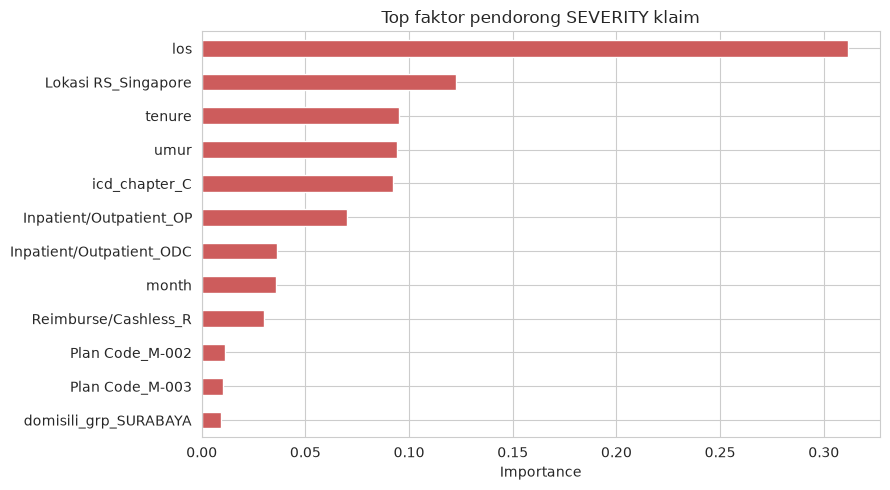

los                         0.311527
Lokasi RS_Singapore         0.122706
tenure                      0.095028
umur                        0.093979
icd_chapter_C               0.092007
Inpatient/Outpatient_OP     0.070159
Inpatient/Outpatient_ODC    0.036470
month                       0.035637
Reimburse/Cashless_R        0.029845
Plan Code_M-002             0.011269
Plan Code_M-003             0.010033
domisili_grp_SURABAYA       0.009476
dtype: float64

In [13]:
imp_sev = (pd.Series(model_sev.feature_importances_, index=X_sev.columns)
           .sort_values(ascending=False).head(12))

imp_sev.iloc[::-1].plot(kind="barh", color="indianred")
plt.title("Top faktor pendorong SEVERITY klaim"); plt.xlabel("Importance")
plt.tight_layout(); plt.show()
imp_sev


### 6.4 Faktor pendorong FREQUENCY (level polis)

Frekuensi adalah **berapa kali sebuah polis mengajukan klaim**. Jadi kita agregasi ke level
polis: `claim_count` per polis, lalu modelkan terhadap profil nasabah (umur, tenure, plan,
gender, domisili). Polis tanpa klaim tetap dimasukkan sebagai `claim_count = 0`.

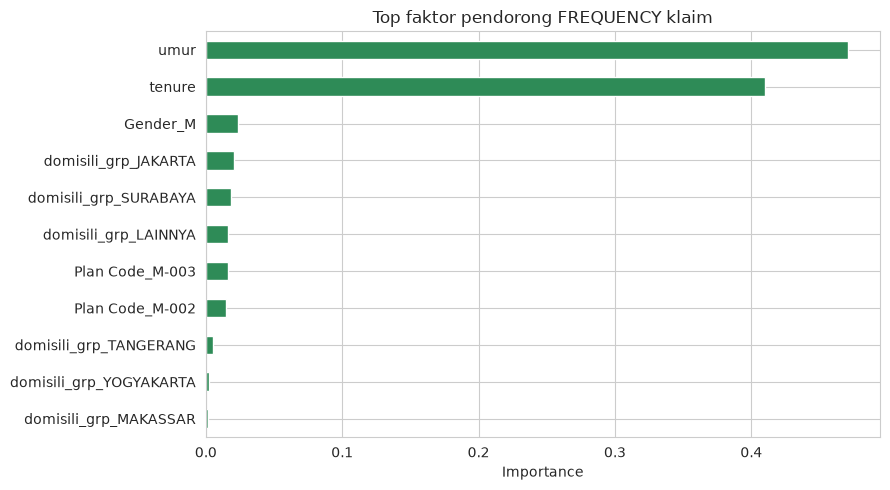

umur                       0.470830
tenure                     0.409965
Gender_M                   0.023228
domisili_grp_JAKARTA       0.020965
domisili_grp_SURABAYA      0.018621
domisili_grp_LAINNYA       0.016462
Plan Code_M-003            0.016421
Plan Code_M-002            0.014933
domisili_grp_TANGERANG     0.004980
domisili_grp_YOGYAKARTA    0.002339
domisili_grp_MAKASSAR      0.001256
dtype: float64

In [14]:
# Jumlah klaim per polis
cc = df_klaim.groupby("Nomor Polis").size().rename("claim_count")

polis_freq = df_polis.copy()
ref_date = df_klaim["Tanggal Pasien Masuk RS"].max()  # akhir periode data
polis_freq["umur"] = ((ref_date - polis_freq["Tanggal Lahir"]).dt.days / 365.25).round(1)
polis_freq["tenure"] = ((ref_date - polis_freq["Tanggal Efektif Polis"]).dt.days / 365.25).clip(lower=0).round(2)
polis_freq = polis_freq.merge(cc, on="Nomor Polis", how="left")
polis_freq["claim_count"] = polis_freq["claim_count"].fillna(0)

top_dom_p = polis_freq["Domisili"].value_counts().head(6).index
polis_freq["domisili_grp"] = np.where(polis_freq["Domisili"].isin(top_dom_p), polis_freq["Domisili"], "LAINNYA")

freq_cols = ["Plan Code", "Gender", "domisili_grp", "umur", "tenure"]
Xf = pd.get_dummies(polis_freq[freq_cols], drop_first=True)
yf = polis_freq["claim_count"]

model_freq = RandomForestRegressor(n_estimators=300, max_depth=10,
                                   min_samples_leaf=3, random_state=RANDOM_STATE, n_jobs=-1)
model_freq.fit(Xf, yf)

imp_freq = pd.Series(model_freq.feature_importances_, index=Xf.columns).sort_values(ascending=False).head(12)
imp_freq.iloc[::-1].plot(kind="barh", color="seagreen")
plt.title("Top faktor pendorong FREQUENCY klaim"); plt.xlabel("Importance")
plt.tight_layout(); plt.show()
imp_freq


## 7. Agregasi Deret Waktu Bulanan

Untuk memproyeksikan tren, kita ringkas data menjadi deret bulanan dengan tiga target:
- **frequency** = jumlah klaim per bulan,
- **severity** = rata-rata nominal klaim per bulan,
- **total_claim** = frequency × severity (secara definisi = total nominal klaim bulan itu).

Karena `total = frequency × severity` bersifat identitas, kita cukup memproyeksikan **frequency
dan severity**, lalu **total diturunkan** darinya. Ini menjaga konsistensi antar-target dan
mengurangi masalah pemodelan dari tiga menjadi dua.

In [15]:
monthly = df.groupby("year_month").agg(
    frequency=("Claim ID", "count"),
    severity=("severity", "mean"),
).reset_index()
monthly["total_claim"] = monthly["frequency"] * monthly["severity"]
monthly["ds"] = pd.to_datetime(monthly["year_month"])
monthly = monthly.sort_values("ds").reset_index(drop=True)

print("Jumlah bulan:", len(monthly))
monthly


Jumlah bulan: 19


,year_month,frequency,severity,total_claim,ds
0,2024-01,302,6.708934e+07,2.026098e+10,2024-01-01
1,2024-02,208,6.663291e+07,1.385965e+10,2024-02-01
2,2024-03,278,5.147935e+07,1.431126e+10,2024-03-01
3,2024-04,239,4.787056e+07,1.144106e+10,2024-04-01
4,2024-05,263,4.643141e+07,1.221146e+10,2024-05-01
5,2024-06,225,5.388963e+07,1.212517e+10,2024-06-01
6,2024-07,257,5.825104e+07,1.497052e+10,2024-07-01
7,2024-08,228,5.926726e+07,1.351294e+10,2024-08-01
8,2024-09,208,5.896211e+07,1.226412e+10,2024-09-01
9,2024-10,274,4.628163e+07,1.268117e+10,2024-10-01


## 8. Pemodelan & Forecasting

### Strategi
Data hanya ~19 bulan, jadi kita gunakan fitur yang sedikit tapi bermakna:
- `trend` — indeks waktu linear (menangkap kenaikan/penurunan jangka panjang),
- `sin`/`cos` bulan — komponen musiman tahunan,
- `lag1` — nilai bulan sebelumnya (autokorelasi).

Kita bandingkan **2 model** (sesuai syarat case): **Linear Regression** dan **Random Forest**,
dan memilih yang **MAPE**-nya terkecil pada data uji (4 bulan terakhir). MAPE dipilih karena
itu metrik resmi kompetisi dan fokus pada kesalahan relatif.

In [16]:
FEATS = ["trend", "sin", "cos", "lag1"]


def build_feats(series):
    """Bangun fitur deret waktu dari DataFrame kolom ['ds','y']."""
    d = series.copy().reset_index(drop=True)
    d["trend"] = np.arange(len(d))
    m = d["ds"].dt.month
    d["sin"] = np.sin(2 * np.pi * m / 12)
    d["cos"] = np.cos(2 * np.pi * m / 12)
    d["lag1"] = d["y"].shift(1)
    return d


def make_models():
    return {
        "Linear Regression": LinearRegression(),
        "Random Forest": RandomForestRegressor(n_estimators=200, max_depth=3,
                                               random_state=RANDOM_STATE, n_jobs=-1),
    }


def compare_models(series, holdout=4):
    """Latih tiap model pada data awal, evaluasi MAPE pada `holdout` bulan terakhir."""
    d = build_feats(series).dropna().reset_index(drop=True)
    split = len(d) - holdout
    tr, te = d.iloc[:split], d.iloc[split:]
    rows = {}
    for name, mdl in make_models().items():
        mdl.fit(tr[FEATS], tr["y"])
        rows[name] = mape(te["y"], mdl.predict(te[FEATS]))
    return rows


### 8.1 Pilih model terbaik per target (berdasarkan MAPE)

In [17]:
def series_of(col):
    return monthly[["ds", col]].rename(columns={col: "y"})

comparison = {}
best_model_name = {}
for col in ["frequency", "severity"]:
    scores = compare_models(series_of(col))
    comparison[col] = scores
    best_model_name[col] = min(scores, key=scores.get)

comp_df = pd.DataFrame(comparison).T
comp_df["Model terpilih"] = pd.Series(best_model_name)
print("MAPE (%) pada 4 bulan uji terakhir:")
comp_df


MAPE (%) pada 4 bulan uji terakhir:


,Linear Regression,Random Forest,Model terpilih
frequency,8.059068,8.135181,Linear Regression
severity,5.417160,7.780385,Linear Regression


### 8.2 Forecast rekursif Agustus 2025 – Desember 2026
Model terbaik dilatih ulang pada seluruh data, lalu memprediksi satu bulan ke depan secara
berantai (prediksi bulan ini menjadi `lag1` bulan berikutnya). Kita proyeksikan sampai akhir
**2026** agar mencakup kebutuhan Kaggle (Agu–Des 2025) sekaligus fokus utama case (tahun 2026).

In [18]:
def recursive_forecast(series, model, steps, start_date):
    hist = series.copy().reset_index(drop=True)
    cur = start_date
    out = []
    for _ in range(steps):
        f = build_feats(hist).dropna()
        model.fit(f[FEATS], f["y"])
        row = {
            "trend": len(hist),
            "sin": np.sin(2 * np.pi * cur.month / 12),
            "cos": np.cos(2 * np.pi * cur.month / 12),
            "lag1": hist["y"].iloc[-1],
        }
        yhat = float(model.predict(pd.DataFrame([row])[FEATS])[0])
        yhat = max(yhat, 0)
        out.append({"ds": cur, "y": yhat})
        hist = pd.concat([hist, pd.DataFrame({"ds": [cur], "y": [yhat]})], ignore_index=True)
        cur = cur + pd.DateOffset(months=1)
    return pd.DataFrame(out)


start = monthly["ds"].max() + pd.DateOffset(months=1)   # 2025-08
horizon = 17                                            # Agu 2025 .. Des 2026

fc = {}
for col in ["frequency", "severity"]:
    mdl = make_models()[best_model_name[col]]
    fc[col] = recursive_forecast(series_of(col), mdl, horizon, start)

forecast = fc["frequency"].rename(columns={"y": "frequency"})
forecast["severity"] = fc["severity"]["y"].values
forecast["total_claim"] = forecast["frequency"] * forecast["severity"]
forecast["year_month"] = forecast["ds"].dt.strftime("%Y-%m")
forecast[["year_month", "frequency", "severity", "total_claim"]]


,year_month,frequency,severity,total_claim
0,2025-08,225.828413,5.379152e+07,1.214765e+10
1,2025-09,241.550277,5.413915e+07,1.307733e+10
2,2025-10,234.826338,5.420274e+07,1.272823e+10
3,2025-11,235.369559,5.421437e+07,1.276041e+10
4,2025-12,231.827607,5.421649e+07,1.256888e+10
5,2026-01,229.239205,5.421688e+07,1.242864e+10
6,2026-02,226.406168,5.439312e+07,1.231494e+10
7,2026-03,224.534784,5.444073e+07,1.222384e+10
8,2026-04,223.659073,5.446446e+07,1.218147e+10
9,2026-05,223.903902,5.448360e+07,1.219909e+10


### 8.3 Visualisasi: histori vs forecast

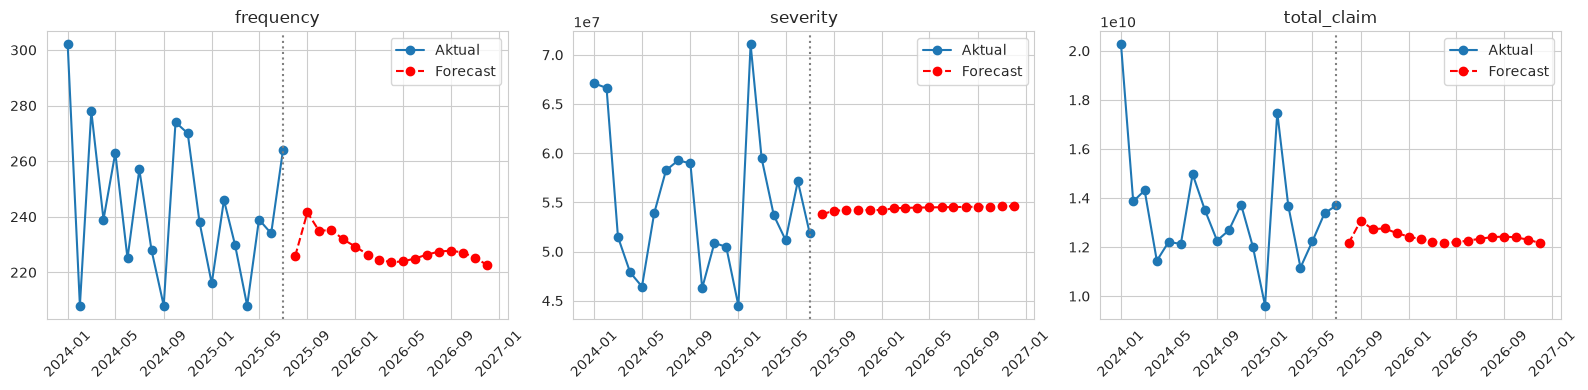

In [19]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for i, col in enumerate(["frequency", "severity", "total_claim"]):
    ax[i].plot(monthly["ds"], monthly[col], marker="o", label="Aktual")
    ax[i].plot(forecast["ds"], forecast[col], marker="o", linestyle="--", color="red", label="Forecast")
    ax[i].axvline(monthly["ds"].max(), color="grey", linestyle=":")
    ax[i].set(title=col); ax[i].legend(); ax[i].tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()


## 9. Output: Submission Kaggle & Proyeksi 2026

### 9.1 File submission (Agustus–Desember 2025)
Format sesuai case: kolom `Id,value` dengan id `YYYY-MM_<Metric>`.

In [20]:
sub_period = forecast[forecast["ds"] <= "2025-12-01"]

rows = []
for _, r in sub_period.iterrows():
    ym = r["year_month"]
    rows.append([f"{ym}_Claim_Frequency", r["frequency"]])
    rows.append([f"{ym}_Claim_Severity", r["severity"]])
    rows.append([f"{ym}_Total_Claim", r["total_claim"]])

submission = pd.DataFrame(rows, columns=["Id", "value"])
submission.to_csv("submission_kaggle.csv", index=False)
print("Tersimpan: submission_kaggle.csv")
submission


Tersimpan: submission_kaggle.csv


,Id,value
0,2025-08_Claim_Frequency,2.258284e+02
1,2025-08_Claim_Severity,5.379152e+07
2,2025-08_Total_Claim,1.214765e+10
3,2025-09_Claim_Frequency,2.415503e+02
4,2025-09_Claim_Severity,5.413915e+07
5,2025-09_Total_Claim,1.307733e+10
6,2025-10_Claim_Frequency,2.348263e+02
7,2025-10_Claim_Severity,5.420274e+07
8,2025-10_Total_Claim,1.272823e+10
9,2025-11_Claim_Frequency,2.353696e+02


### 9.2 Proyeksi tahunan 2026
Ringkasan proyeksi setahun penuh 2026 — angka yang dipakai untuk pengambilan keputusan bisnis.

In [21]:
f2026 = forecast[(forecast["ds"] >= "2026-01-01") & (forecast["ds"] <= "2026-12-01")]

ringkas_2026 = {
    "Total klaim setahun (Rp)": f2026["total_claim"].sum(),
    "Rata-rata frekuensi / bulan": f2026["frequency"].mean(),
    "Rata-rata severity / klaim (Rp)": f2026["severity"].mean(),
}
for k, v in ringkas_2026.items():
    print(f"{k:35s}: {v:,.0f}")


Total klaim setahun (Rp)           : 147,631,080,895
Rata-rata frekuensi / bulan        : 226
Rata-rata severity / klaim (Rp)    : 54,489,809


## 10. Kesimpulan & Rekomendasi

**Temuan faktor.**
- **Severity** paling dipengaruhi oleh jenis rawat (rawat inap), lama rawat (LOS), lokasi RS,
  bab penyakit (ICD), dan umur — lihat Bagian 6.3. Artinya kasus rawat inap berdurasi panjang
  dan penyakit berat (mis. neoplasma) adalah pendorong biaya utama.
- **Frequency** lebih dipengaruhi umur, tenure, dan plan code — lihat Bagian 6.4.

**Tren.** Frekuensi bulanan stabil; total klaim digerakkan terutama oleh **severity** yang
volatil karena klaim ekstrem. Proyeksi 2026 menunjukkan level klaim yang relatif bertahan
(lihat Bagian 9.2).

**Rekomendasi bisnis.**
1. **Seleksi risiko & pricing** berbasis pendorong severity (jenis rawat, penyakit berat,
   lokasi RS luar negeri) — pertimbangkan penyesuaian manfaat/premi pada segmen berbiaya tinggi.
2. **Pencegahan & deteksi dini** untuk penyakit kronis/berat pada kelompok umur lanjut untuk
   menekan severity.
3. **Manajemen jaringan RS** — mengarahkan ke provider dengan biaya wajar dapat menurunkan
   severity tanpa mengurangi kualitas layanan.
4. **Pemantauan bulanan** total klaim (freq × severity) sebagai indikator profitabilitas
   portofolio, dengan perhatian khusus pada lonjakan severity.

**Catatan metodologis.** Model sengaja dijaga sederhana (Linear Regression & Random Forest
ringan) karena data bulanan hanya 19 titik dan relatif datar — model kompleks akan overfit.
Semua fitur bebas dari kebocoran target, sehingga metrik evaluasi mencerminkan performa yang
jujur dan dapat direproduksi dari notebook ini.
